# MONAI XAI

## Imports

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from PIL import Image

from monai.networks.nets import densenet121
from monai.transforms import (
    Compose,
    LoadImage,
    EnsureChannelFirst,
    Resize,
    ScaleIntensity,
    EnsureType,
)

C:\Users\user\anaconda3\envs\monai\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Check GPU

In [6]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 5070


## Config

In [7]:
PROJECT_DIR = r"C:\Users\user\Desktop\MONAI"

MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "models",
    "monai_densenet121.pt"
)

DATA_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "brain-tumor-mri-classification",
    "merged_dataset_v3",
    "images"
)

print("Model:", MODEL_PATH)
print("Data:", DATA_DIR)

Model: C:\Users\user\Desktop\MONAI\models\monai_densenet121.pt
Data: C:\Users\user\Desktop\MONAI\data\brain-tumor-mri-classification\merged_dataset_v3\images


In [8]:
print(os.path.exists(MODEL_PATH))

True


In [9]:
class_names = [
    "glioma",
    "meningioma",
    "no_tumor",
    "pituitary"
]

num_classes = len(class_names)

print(class_names)

['glioma', 'meningioma', 'no_tumor', 'pituitary']


## Load Model

In [10]:
model = densenet121(
    spatial_dims=2,
    in_channels=3,
    out_channels=4
)

model = model.to(device)

In [11]:
save_dict={"model": model}

In [13]:
checkpoint = torch.load(
    MODEL_PATH,
    map_location=device
)

model.load_state_dict(checkpoint)

model.eval()

print("Model loaded successfully.")

Model loaded successfully.


In [14]:
for name, module in model.named_modules():
    print(name, "->", type(module).__name__)

 -> DenseNet121
features -> Sequential
features.conv0 -> Conv2d
features.norm0 -> BatchNorm2d
features.relu0 -> ReLU
features.pool0 -> MaxPool2d
features.denseblock1 -> _DenseBlock
features.denseblock1.denselayer1 -> _DenseLayer
features.denseblock1.denselayer1.layers -> Sequential
features.denseblock1.denselayer1.layers.norm1 -> BatchNorm2d
features.denseblock1.denselayer1.layers.relu1 -> ReLU
features.denseblock1.denselayer1.layers.conv1 -> Conv2d
features.denseblock1.denselayer1.layers.norm2 -> BatchNorm2d
features.denseblock1.denselayer1.layers.relu2 -> ReLU
features.denseblock1.denselayer1.layers.conv2 -> Conv2d
features.denseblock1.denselayer2 -> _DenseLayer
features.denseblock1.denselayer2.layers -> Sequential
features.denseblock1.denselayer2.layers.norm1 -> BatchNorm2d
features.denseblock1.denselayer2.layers.relu1 -> ReLU
features.denseblock1.denselayer2.layers.conv1 -> Conv2d
features.denseblock1.denselayer2.layers.norm2 -> BatchNorm2d
features.denseblock1.denselayer2.layers.r

In [15]:
transform = Compose([
    LoadImage(image_only=True),
    EnsureChannelFirst(),
    Resize((224, 224)),
    ScaleIntensity(),
    EnsureType(),
])

## Select 8 random images

In [21]:
import random

TEST_DIR = os.path.join(DATA_DIR, "test")

random.seed(42)

selected_images = []

for class_name in class_names:
    class_dir = os.path.join(TEST_DIR, class_name)

    images = [
        os.path.join(class_dir, f)
        for f in os.listdir(class_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    selected = random.sample(images, min(2, len(images)))

    for image_path in selected:
        selected_images.append({
            "path": image_path,
            "true_class": class_name
        })

print("Selected images:", len(selected_images))

for item in selected_images:
    print(item["true_class"], "->", os.path.basename(item["path"]))

Selected images: 8
glioma -> rf_test_glioma_739.jpg
glioma -> rf_test_glioma_728.jpg
meningioma -> rf_test_meningioma_538.jpg
meningioma -> rf_test_meningioma_508.jpg
no_tumor -> rf_test_no_tumor_450.jpg
no_tumor -> rf_test_no_tumor_449.jpg
pituitary -> rf_test_pituitary_558.jpg
pituitary -> rf_test_pituitary_597.jpg


In [22]:
target_layer = model.features.denseblock4

## Apply GRAD CAM

In [23]:
def generate_gradcam(model, image_path, target_layer):
    activations = None
    gradients = None

    def forward_hook(module, inputs, output):
        nonlocal activations
        activations = output

    def backward_hook(module, grad_input, grad_output):
        nonlocal gradients
        gradients = grad_output[0]

    forward_handle = target_layer.register_forward_hook(forward_hook)
    backward_handle = target_layer.register_full_backward_hook(backward_hook)

    # Preprocess image
    image = transform(image_path)

    input_tensor = image.unsqueeze(0).to(device)

    # Forward pass
    model.zero_grad()

    output = model(input_tensor)

    probabilities = F.softmax(output, dim=1)

    predicted_class = output.argmax(dim=1).item()
    confidence = probabilities[0, predicted_class].item()

    # Backward pass
    class_score = output[0, predicted_class]
    class_score.backward()

    # Grad-CAM
    weights = gradients.mean(
        dim=(2, 3),
        keepdim=True
    )

    cam = (weights * activations).sum(
        dim=1,
        keepdim=True
    )

    cam = F.relu(cam)

    cam = F.interpolate(
        cam,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    cam = cam.squeeze()

    # Normalize
    cam = cam - cam.min()

    if cam.max() > 0:
        cam = cam / cam.max()

    cam = cam.detach().cpu().numpy()

    # Image for visualization
    display_image = image.permute(1, 2, 0).cpu().numpy()

    # Normalize display image
    display_image = display_image - display_image.min()

    if display_image.max() > 0:
        display_image = display_image / display_image.max()

    # Remove hooks
    forward_handle.remove()
    backward_handle.remove()

    return (
        display_image,
        cam,
        predicted_class,
        confidence
    )

In [24]:
results = []

for item in selected_images:

    image_path = item["path"]
    true_class = item["true_class"]

    display_image, cam, predicted_class, confidence = generate_gradcam(
        model,
        image_path,
        target_layer
    )

    results.append({
        "path": image_path,
        "true_class": true_class,
        "predicted_class": class_names[predicted_class],
        "confidence": confidence,
        "image": display_image,
        "cam": cam
    })

print("Grad-CAM generated for", len(results), "images.")

Grad-CAM generated for 8 images.


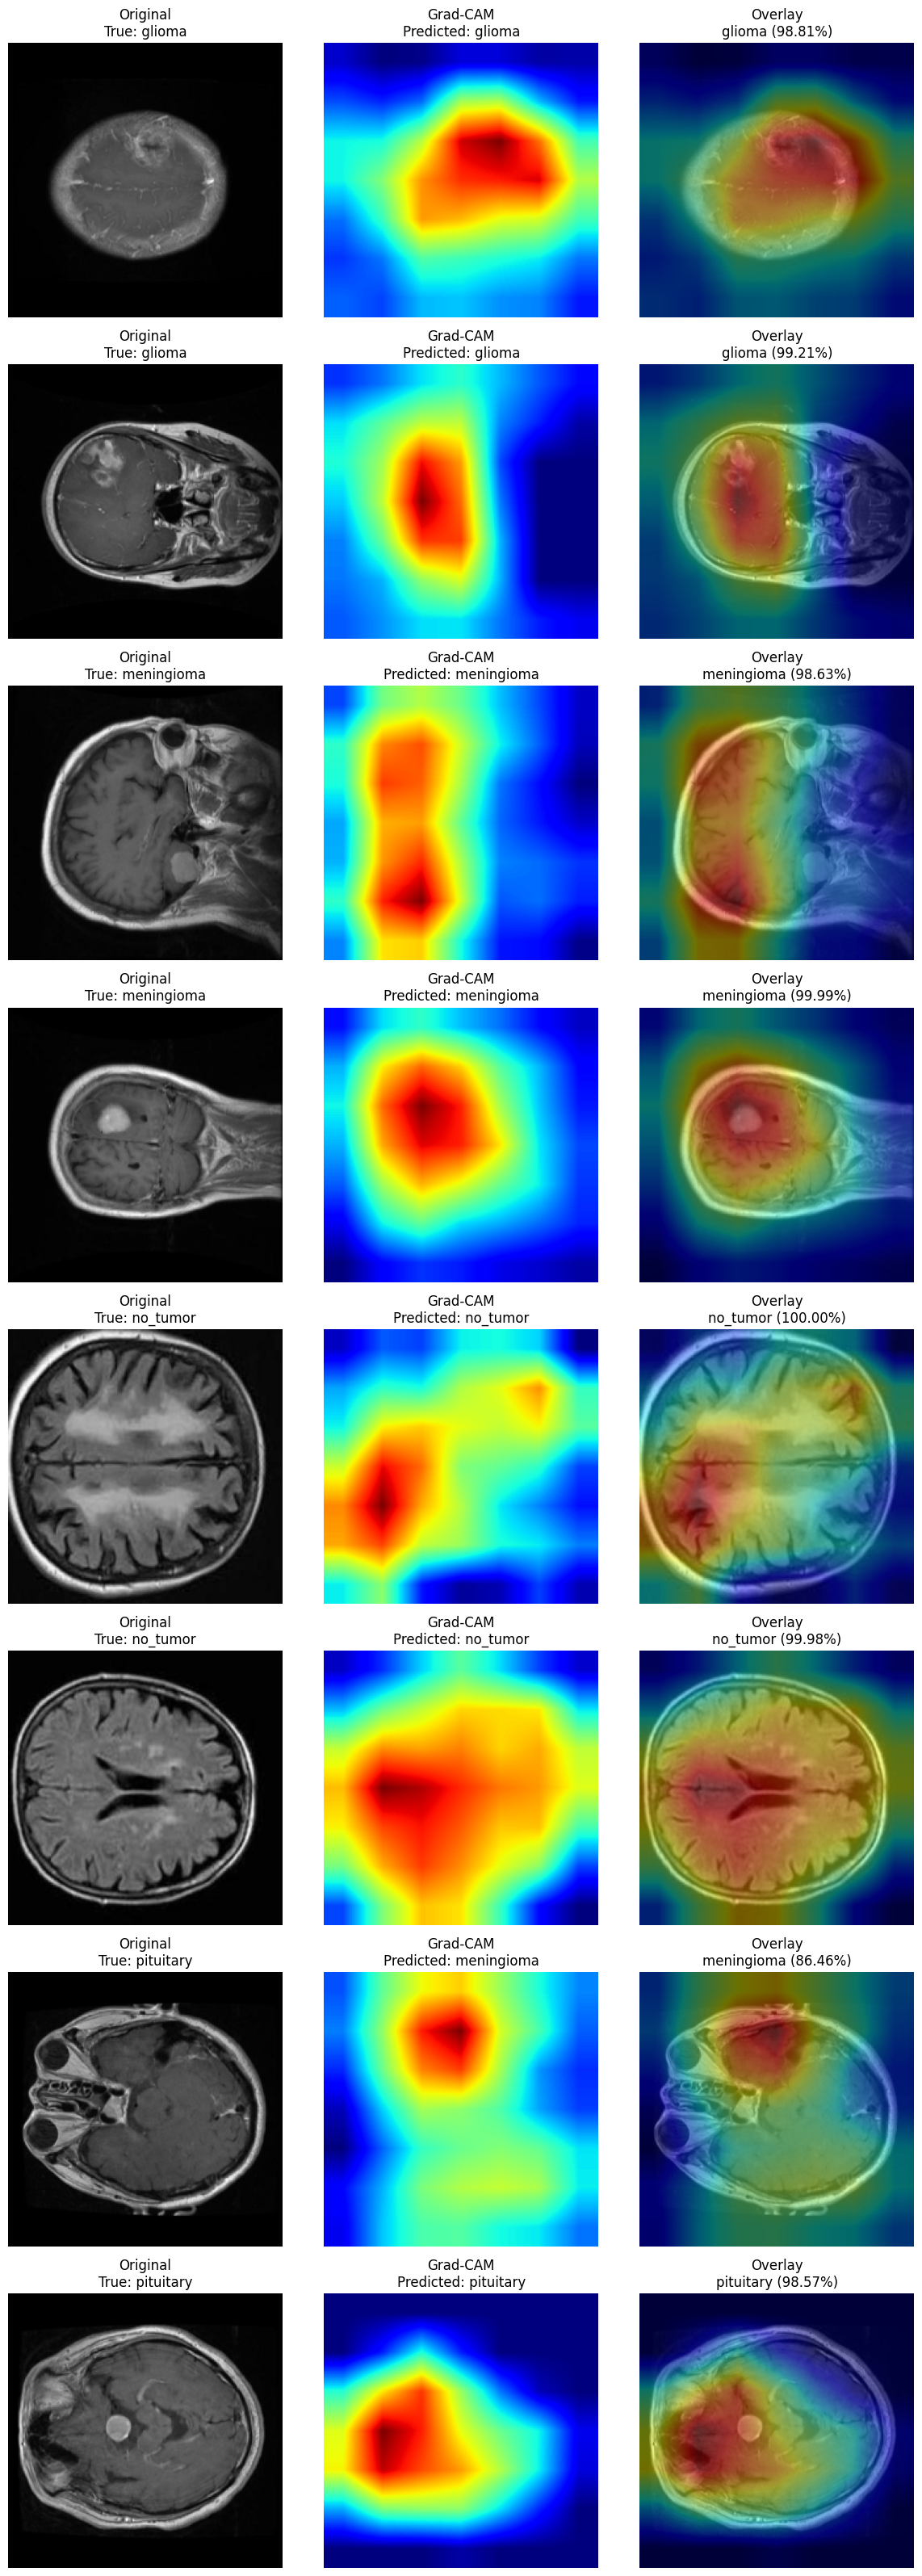

In [25]:
n = len(results)

fig, axes = plt.subplots(
    n,
    3,
    figsize=(12, 4 * n)
)

if n == 1:
    axes = np.expand_dims(axes, axis=0)

for i, result in enumerate(results):

    image = result["image"]
    cam = result["cam"]

    true_class = result["true_class"]
    predicted_class = result["predicted_class"]
    confidence = result["confidence"]

    # Original
    axes[i, 0].imshow(image)
    axes[i, 0].set_title(
        f"Original\nTrue: {true_class}"
    )
    axes[i, 0].axis("off")

    # Heatmap
    axes[i, 1].imshow(cam, cmap="jet")
    axes[i, 1].set_title(
        f"Grad-CAM\nPredicted: {predicted_class}"
    )
    axes[i, 1].axis("off")

    # Overlay
    axes[i, 2].imshow(image)
    axes[i, 2].imshow(
        cam,
        cmap="jet",
        alpha=0.45
    )

    axes[i, 2].set_title(
        f"Overlay\n"
        f"{predicted_class} ({confidence:.2%})"
    )

    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

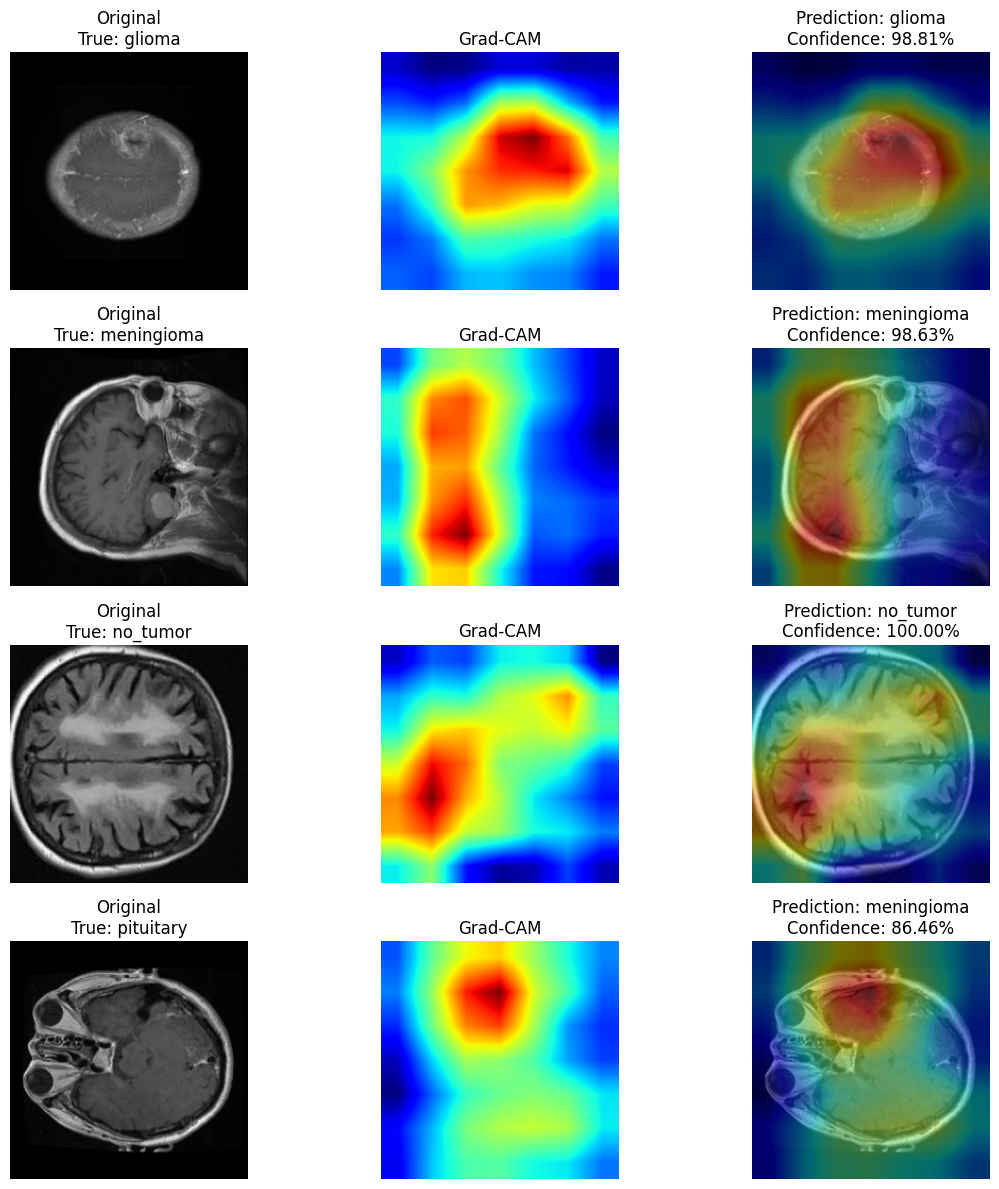

In [26]:
one_per_class = []

for class_name in class_names:
    matches = [
        r for r in results
        if r["true_class"] == class_name
    ]

    if matches:
        one_per_class.append(matches[0])

fig, axes = plt.subplots(
    len(one_per_class),
    3,
    figsize=(12, 12)
)

for i, result in enumerate(one_per_class):

    image = result["image"]
    cam = result["cam"]

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(
        f"Original\nTrue: {result['true_class']}"
    )
    axes[i, 0].axis("off")

    axes[i, 1].imshow(cam, cmap="jet")
    axes[i, 1].set_title("Grad-CAM")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(image)
    axes[i, 2].imshow(
        cam,
        cmap="jet",
        alpha=0.45
    )
    axes[i, 2].set_title(
        f"Prediction: {result['predicted_class']}\n"
        f"Confidence: {result['confidence']:.2%}"
    )
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()